<a href="https://colab.research.google.com/github/Torkev404/BeastTraining/blob/main/Aitor_Kevin_Data_Analyst_Admission%20Proyect_OC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PROJET D'ADMISSION OPENCLASSROOMS AOÛT 2026:

ENERGIES RENOUVELABLES VS EMISSIONS DANS L'UNION EUROPEENNE 2022

Candidat : Aitor Kevin Eteo Mba

Source des Données : Our World in Data


EXPLORATION INITIALE ET NETTOYAGE




In [44]:
import pandas as pd

In [45]:
link = 'https://raw.githubusercontent.com/owid/energy-data/master/owid-energy-data.csv'
dataOg = pd.read_csv(link)
display(dataOg)


,country,year,iso_code,population,gdp,biofuel_cons_change_pct,biofuel_cons_change_twh,biofuel_cons_per_capita,biofuel_consumption,biofuel_elec_per_capita,...,solar_share_elec,solar_share_energy,wind_cons_change_pct,wind_cons_change_twh,wind_consumption,wind_elec_per_capita,wind_electricity,wind_energy_per_capita,wind_share_elec,wind_share_energy
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
4,ASEAN (Ember),2004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23372,Zimbabwe,2020,ZWE,15526887.0,2.317871e+10,NaN,0.0,0.0,0.0,6.440,...,0.298,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,NaN
23373,Zimbabwe,2021,ZWE,15797220.0,2.514009e+10,NaN,0.0,0.0,0.0,6.963,...,0.233,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,NaN
23374,Zimbabwe,2022,ZWE,16069061.0,2.590159e+10,NaN,0.0,0.0,0.0,6.845,...,0.336,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,NaN
23375,Zimbabwe,2023,ZWE,16340829.0,NaN,NaN,0.0,0.0,0.0,7.344,...,0.300,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,NaN


In [46]:
# pour filtrage
countriesEu = ['Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Ireland', 'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'Netherlands', 'Poland', 'Portugal', 'Romania', 'Slovakia', 'Slovenia', 'Spain', 'Sweden']
# pour filtrage par colonnes relevantes
colonnesRelevantes = ['country', 'year', 'population', 'gdp', 'renewables_share_elec', 'fossil_share_elec', 'per_capita_electricity', 'greenhouse_gas_emissions']
# application des filtres
dataEu = dataOg[dataOg['country'].isin(countriesEu)].copy()
dataEu2022 = dataEu[dataEu['year'] == 2022][colonnesRelevantes].reset_index(drop=True).copy()

# affichage du DataFrame filtré pour vue globale
display(dataEu2022)



,country,year,population,gdp,renewables_share_elec,fossil_share_elec,per_capita_electricity,greenhouse_gas_emissions
0,Austria,2022,9064678.0,3.988154e+11,78.191,21.809,7112.222,9.08
1,Belgium,2022,11641814.0,4.896784e+11,25.898,27.584,8102.689,13.15
2,Bulgaria,2022,6825862.0,1.383902e+11,19.153,48.111,7366.103,23.95
3,Croatia,2022,3907031.0,1.022846e+11,63.475,36.525,3608.879,3.45
4,Cyprus,2022,1331376.0,3.425501e+10,16.730,83.270,3950.800,2.92
5,Czechia,2022,10673216.0,3.429668e+11,12.863,50.090,7844.871,40.89
6,Denmark,2022,5902901.0,2.994290e+11,80.859,19.141,5956.393,7.16
7,Estonia,2022,1350093.0,3.999986e+10,31.991,68.009,6621.766,4.36
8,Finland,2022,5569300.0,2.261548e+11,53.568,11.320,12958.540,9.38
9,France,2022,66277412.0,2.671569e+12,24.201,12.883,7068.019,36.79


In [47]:
# inspection du DataFrame
dataEu2022.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   country                   27 non-null     object 
 1   year                      27 non-null     int64  
 2   population                27 non-null     float64
 3   gdp                       27 non-null     float64
 4   renewables_share_elec     27 non-null     float64
 5   fossil_share_elec         27 non-null     float64
 6   per_capita_electricity    27 non-null     float64
 7   greenhouse_gas_emissions  27 non-null     float64
dtypes: float64(6), int64(1), object(1)
memory usage: 1.8+ KB


In [48]:
# quête de NaN (même si j'ai déjà vu qu'il n'y en a pas)
print(dataEu2022.isna().sum())

country                     0
year                        0
population                  0
gdp                         0
renewables_share_elec       0
fossil_share_elec           0
per_capita_electricity      0
greenhouse_gas_emissions    0
dtype: int64


In [49]:
# création de colonne compléménetaire afin de connaître les émissions de gas à effet de serre par habitant
dataEu2022 ['per_capita_emissions'] = (dataEu2022['greenhouse_gas_emissions']*1e6)/(dataEu2022['population'])

In [50]:
display(dataEu2022)

,country,year,population,gdp,renewables_share_elec,fossil_share_elec,per_capita_electricity,greenhouse_gas_emissions,per_capita_emissions
0,Austria,2022,9064678.0,3.988154e+11,78.191,21.809,7112.222,9.08,1.001690
1,Belgium,2022,11641814.0,4.896784e+11,25.898,27.584,8102.689,13.15,1.129549
2,Bulgaria,2022,6825862.0,1.383902e+11,19.153,48.111,7366.103,23.95,3.508714
3,Croatia,2022,3907031.0,1.022846e+11,63.475,36.525,3608.879,3.45,0.883023
4,Cyprus,2022,1331376.0,3.425501e+10,16.730,83.270,3950.800,2.92,2.193220
5,Czechia,2022,10673216.0,3.429668e+11,12.863,50.090,7844.871,40.89,3.831085
6,Denmark,2022,5902901.0,2.994290e+11,80.859,19.141,5956.393,7.16,1.212963
7,Estonia,2022,1350093.0,3.999986e+10,31.991,68.009,6621.766,4.36,3.229407
8,Finland,2022,5569300.0,2.261548e+11,53.568,11.320,12958.540,9.38,1.684233
9,France,2022,66277412.0,2.671569e+12,24.201,12.883,7068.019,36.79,0.555091


TENDANCE CENTRALE, DISPERSION ET FORME

In [51]:
# indicateurs de tendance centrale et de dispersion
dataStats = dataEu2022[['renewables_share_elec', 'fossil_share_elec', 'per_capita_emissions']].describe().T
dataStats['iqr'] = dataStats['75%'] - dataStats['25%']
dataStats['skewness'] = dataEu2022[['renewables_share_elec', 'fossil_share_elec','per_capita_emissions' ]].skew()
dataStats['kurtosis'] = dataEu2022[['renewables_share_elec', 'fossil_share_elec','per_capita_emissions' ]].kurt()

display(dataStats)

# pêche à l'outlier
def outliers(df, series) :
  q1 = series.quantile(0.25)
  q3 = series.quantile(0.75)
  iqr = q3 - q1
  limHaut = q3 + 1.5 * iqr
  limBas = q1 - 1.5 * iqr
  return  df[(series < limBas) | (series > limHaut)]

outliersFossil = outliers(dataEu2022, dataEu2022['fossil_share_elec'])
print('Outliers Energie Fossile')
display(outliersFossil)

outliersRenouvelables = outliers(dataEu2022, dataEu2022['renewables_share_elec'])
print('Outliers Energies Renouvelables')
display(outliersRenouvelables)

outliersEmissions = outliers(dataEu2022, dataEu2022['per_capita_emissions'])
print('Outliers Emissions CO2')
display(outliersEmissions)


,count,mean,std,min,25%,50%,75%,max,iqr,skewness,kurtosis
renewables_share_elec,27.0,43.273296,22.794714,12.863000,23.065000,40.097000,61.534500,85.950000,38.469500,0.466708,-1.040089
fossil_share_elec,27.0,40.402222,23.189058,1.664000,22.932500,36.591000,56.493000,86.957000,33.560500,0.428349,-0.653211
per_capita_emissions,27.0,1.612363,1.042433,0.259148,0.848064,1.303619,2.184722,3.831085,1.336658,0.685735,-0.496954


Outliers Energie Fossile


,country,year,population,gdp,renewables_share_elec,fossil_share_elec,per_capita_electricity,greenhouse_gas_emissions,per_capita_emissions


Outliers Energies Renouvelables


,country,year,population,gdp,renewables_share_elec,fossil_share_elec,per_capita_electricity,greenhouse_gas_emissions,per_capita_emissions


Outliers Emissions CO2


,country,year,population,gdp,renewables_share_elec,fossil_share_elec,per_capita_electricity,greenhouse_gas_emissions,per_capita_emissions


INDICATEURS DE DISTRIBUTION

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

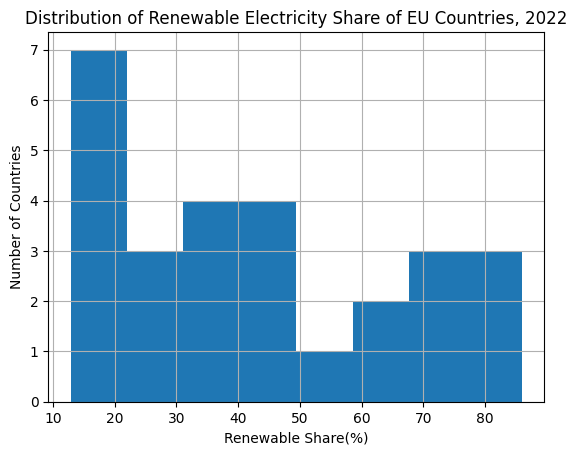

In [53]:
dataEu2022['renewables_share_elec'].hist(bins=8)
plt.title("Distribution of Renewable Electricity Share of EU Countries, 2022")
plt.xlabel("Renewable Share(%)")
plt.ylabel("Number of Countries")
plt.show()

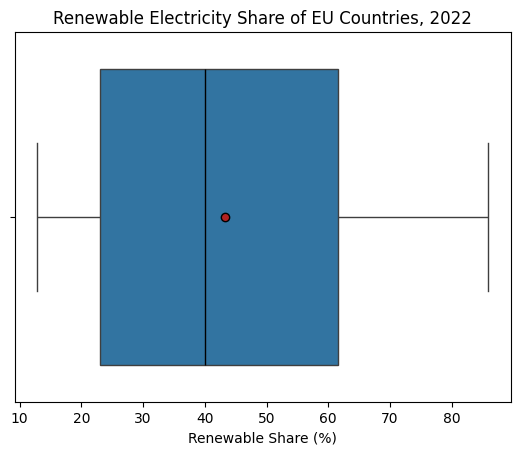

In [54]:
medianprops = {'color': 'black'}
meanprops = {'marker': 'o', 'markeredgecolor': 'black', 'markerfacecolor': 'firebrick'}
sns.boxplot(x=dataEu2022["renewables_share_elec"], showmeans=True, meanprops=meanprops, medianprops=medianprops)
plt.title("Renewable Electricity Share of EU Countries, 2022")
plt.xlabel("Renewable Share (%)")

plt.show()

VISUALISATION ET INDICATEUR DE CONCENTRATION

In [55]:
import numpy as np

/tmp/ipykernel_4512/3878327453.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


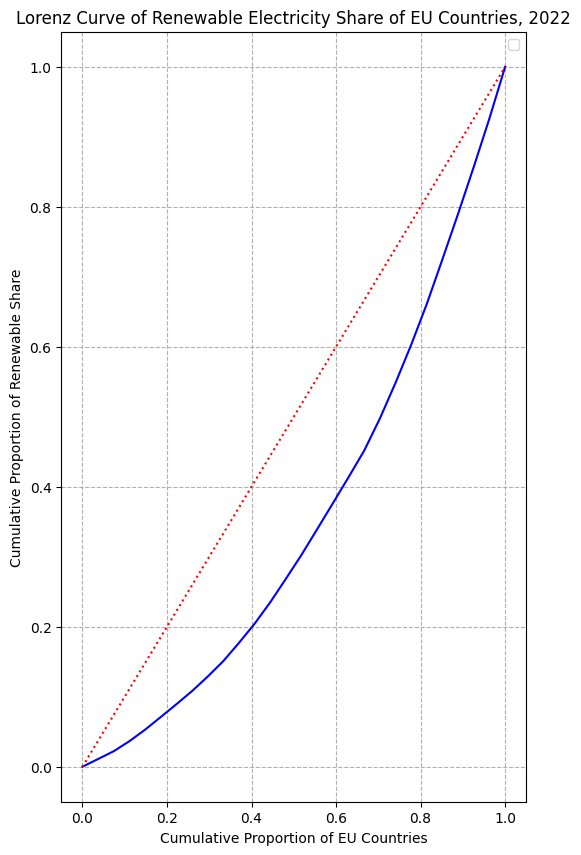

Aire Sous Courbe: 0.3537
Coefficient Gini: 10.0000


In [56]:
renovablesEu = dataEu2022['renewables_share_elec'].values
n = len(renovablesEu)
lorenz = np.cumsum(np.sort(renovablesEu))/ renovablesEu.sum()

lorenz = np.append([0], lorenz)

xaxis = np.linspace(0, 1, len(lorenz))

plt.figure(figsize=(6, 10))
plt.plot(xaxis, lorenz, drawstyle='default', color='blue')
plt.plot([0, 1], [0, 1], color='red', linestyle='dotted')

plt.title("Lorenz Curve of Renewable Electricity Share of EU Countries, 2022")
plt.xlabel('Cumulative Proportion of EU Countries')
plt.ylabel('Cumulative Proportion of Renewable Share')
plt.legend()
plt.grid(True, linestyle='--')
plt.show()

ASC = (lorenz.sum() - lorenz[-1] / 2 - lorenz[0] / 2)/ n
S = 0.5 - ASC
gini = 2 * 5

print(f"Aire Sous Courbe: {ASC:.4f}")
print(f"Coefficient Gini: {gini:.4f}")

ANALYSES BIVARIEES

In [57]:
import scipy.stats as st

In [58]:
X = dataEu2022['renewables_share_elec'].values
Y = dataEu2022['per_capita_emissions'].values
n= len(X)

covariance = np.cov(X, Y, ddof = 0)[0, 1]
r, pValue = st.pearsonr(X, Y)

varianceX = np.var(X, ddof= 0)
a = covariance/varianceX
b = Y.mean() - a* X.mean()

yEst = a * X + b

SCT = np.sum((Y - Y.mean()**2))
SCE = np.sum((Y - yEst)**2)
SCM = np.sum((yEst - Y.mean()**2))

rSquared = SCM/SCT



In [59]:
print('RESULTATS ANALYSE BIVARIEE POURCENTAGE RENOUVELABLES VS EMISSIONS')
print(' ')
print(f'Covariance {covariance:.4f}')
print(f'Corrélation Pearson: {r:.4f}')
print(f'Ligne Régression: yEst = {a:.4f} * X + {b:.4f}')
print(f'Coefficient Détermination: {rSquared:.4f}')

RESULTATS ANALYSE BIVARIEE POURCENTAGE RENOUVELABLES VS EMISSIONS
 
Covariance -13.6121
Corrélation Pearson: -0.5949
Ligne Régression: yEst = -0.0272 * X + 2.7896
Coefficient Détermination: 1.0000


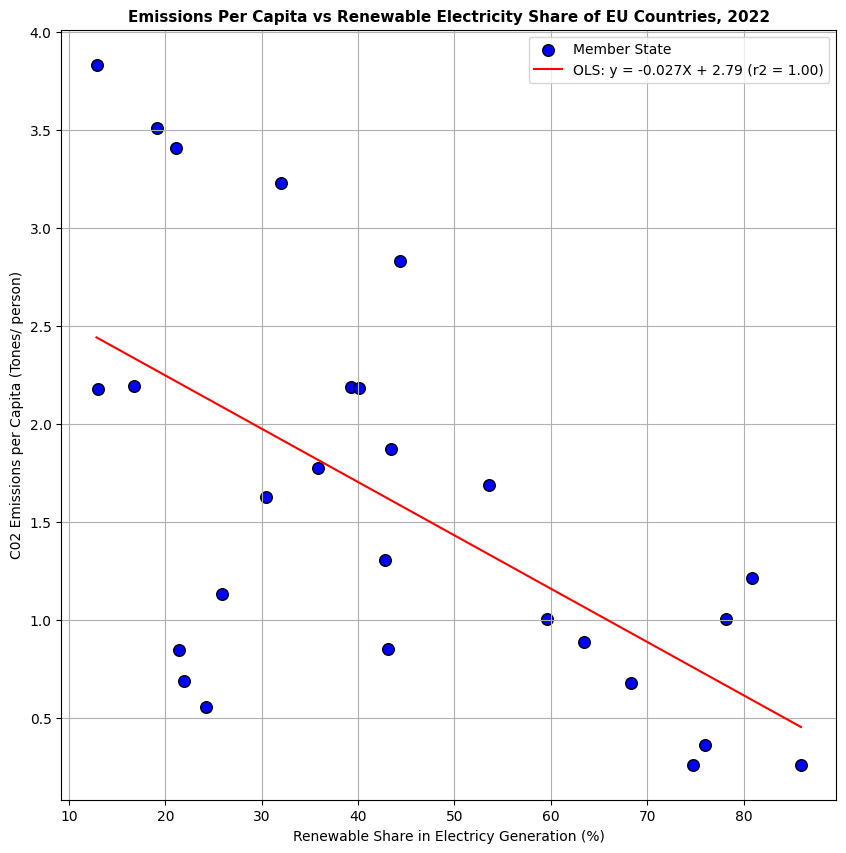

In [68]:
plt.figure(figsize=(10, 10))
plt.scatter(X, Y, color='blue', edgecolors='black', s= 70, label='Member State')

xLine = np.linspace(X.min(), X.max(), 100)
plt.plot(xLine, a * xLine + b, color= 'red', label=f'OLS: y = {a:.3f}X + {b:.2f} (r2 = {rSquared:.2f})')

plt.title('Emissions Per Capita vs Renewable Electricity Share of EU Countries, 2022', fontsize=11, fontweight='bold')
plt.xlabel('Renewable Share in Electricy Generation (%)')
plt.ylabel('C02 Emissions per Capita (Tones/ person)')
plt.legend()
plt.grid(True, linestyle='solid')
plt.show()


In [61]:
import plotly.express as px

In [69]:

fig = px.choropleth(dataEu2022, locations='country', locationmode='country names', color='renewables_share_elec', scope='europe', color_continuous_scale='Viridis', labels={'renewables_share_elec': 'Renewable Share (%)'}, title='Renewable Electricity Across UE Countries, 2022')
fig.update_geos(center=dict(lat=54, lon=15), projection_scale=3.2, visible=False)
fig.update_layout(margin=dict(l=0, r=0, t=50, b=0), height=600)
fig.show()

In [72]:
fig = px.choropleth(dataEu2022, locations='country', locationmode='country names', color='per_capita_emissions', scope='europe', color_continuous_scale='Reds', labels={'per_capita_emissions': 'Emissions per Capita (Tones/Citizen)'}, title='CO2 Emissions Accross EU Countries, 2022')
fig.update_geos(center=dict(lat=54, lon=15), projection_scale=3.2, visible=False)
fig.update_layout(margin=dict(l=0, r=0, t=50, b=0), height=600)
fig.show()